Model berhasil dimuat!

Daftar kelas:
['Athletic Bilbao', 'Atletico Madrid', 'Barcelona', 'Celta Vigo', 'Deportivo Alaves', 'Espanyol', 'Getafe', 'Girona', 'Las Palmas', 'Leganes', 'Mallorca', 'Osasuna', 'Rayo Vallecano', 'Real Betis', 'Real Madrid', 'Real Sociedad', 'Real Valladolid', 'Sevilla', 'Valencia', 'Villarreal']

Jumlah kelas: 20
Jumlah output model: 20

Contoh lokasi gambar:
testing/real_madrid.jpg

          HASIL PENGUJIAN CNN
Label Sebenarnya : Real Madrid
Hasil Prediksi   : Real Madrid
Confidence       : 100.00%
Status Prediksi  : BENAR


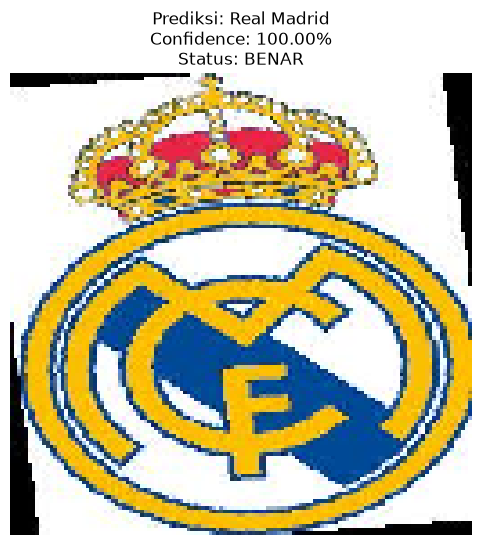

In [10]:

import tensorflow as tf
import numpy as np
import json
import os
import matplotlib.pyplot as plt

# ==================================================
# 1. MEMUAT MODEL CNN
# ==================================================

model = tf.keras.models.load_model(
    "model_laliga.keras"
)

print("Model berhasil dimuat!")

# ==================================================
# 2. MEMUAT NAMA KELAS
# ==================================================

# Mengambil nama kelas dari dataset training
dataset_path = "Laliga teams/Laliga teams"

# Jika folder dataset berada di dalam folder Laliga teams,
# gunakan lokasi berikut:
if os.path.isdir(
    os.path.join(dataset_path, "Laliga teams")
):
    dataset_path = os.path.join(
        dataset_path,
        "Laliga teams"
    )

class_names = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(
        os.path.join(dataset_path, folder)
    )
])

print("\nDaftar kelas:")
print(class_names)

print("\nJumlah kelas:", len(class_names))

# ==================================================
# 3. MEMERIKSA JUMLAH OUTPUT MODEL
# ==================================================

jumlah_output = model.output_shape[-1]

print("Jumlah output model:", jumlah_output)

if len(class_names) != jumlah_output:

    raise ValueError(
        "\nERROR: Jumlah kelas tidak sesuai dengan model!\n"
        "Pastikan model dilatih menggunakan dataset "
        "dengan struktur folder yang benar."
    )

# ==================================================
# 4. MEMASUKKAN GAMBAR UNTUK PENGUJIAN
# ==================================================

print("\nContoh lokasi gambar:")
print("testing/real_madrid.jpg")

image_path = input(
    "\nMasukkan lokasi gambar yang ingin diuji: "
).strip().strip('"')

# Memastikan gambar tersedia
if not os.path.exists(image_path):

    raise FileNotFoundError(
        f"Gambar tidak ditemukan: {image_path}"
    )

# ==================================================
# 5. MEMASUKKAN LABEL SEBENARNYA
# ==================================================

label_asli = input(
    "Masukkan nama klub sebenarnya: "
).strip()

# ==================================================
# 6. MEMBACA DAN MEMPROSES GAMBAR
# ==================================================

img = tf.keras.utils.load_img(
    image_path,
    target_size=(128, 128)
)

img_array = tf.keras.utils.img_to_array(
    img
)

img_array = np.expand_dims(
    img_array,
    axis=0
)

# ==================================================
# 7. MELAKUKAN PREDIKSI
# ==================================================

prediction = model.predict(
    img_array,
    verbose=0
)

predicted_index = np.argmax(
    prediction[0]
)

predicted_class = class_names[
    predicted_index
]

confidence = (
    prediction[0][predicted_index] * 100
)

# ==================================================
# 8. MEMBANDINGKAN HASIL PREDIKSI
# ==================================================

if label_asli.lower() == predicted_class.lower():

    status = "BENAR"

else:

    status = "SALAH"

# ==================================================
# 9. MENAMPILKAN HASIL PENGUJIAN
# ==================================================

print("\n" + "=" * 45)

print("          HASIL PENGUJIAN CNN")

print("=" * 45)

print("Label Sebenarnya :", label_asli)

print("Hasil Prediksi   :", predicted_class)

print(f"Confidence       : {confidence:.2f}%")

print("Status Prediksi  :", status)

print("=" * 45)

# ==================================================
# 10. MENAMPILKAN GAMBAR
# ==================================================

plt.figure(figsize=(6, 6))

plt.imshow(img)

plt.title(
    f"Prediksi: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%\n"
    f"Status: {status}"
)

plt.axis("off")

plt.show()
